# 10 기준선 A를 B와 같은 학습 데이터로, 닮은 단어 확인, Whisper의 처음 듣는 단어

08에서 팀 모델 B는 "명령 아님" 단어를 공식 학습 목록에서 전부 쓰기로 했습니다(학습 79,392개, E13). 그런데 기준선 A(Whisper, E08)는 07의 목록(단어마다 153개, 학습 34,829개)으로 학습한 상태라 **A와 B의 학습 데이터가 다릅니다**. 여기서 A도 같은 79,392개로 맞추고, 09에서 남은 두 가지를 확인합니다.

1. **tree와 three는 소리가 비슷한데 다른 묶음이었습니다**(tree는 묶음 3, three는 묶음 2). 한쪽을 뺄 때 다른 쪽은 학습에 들어 있어, 둘이 처음 들어도 거의 안 샌 이유가 "명령과 안 닮아서"인지 "학습한 짝과 닮아서"인지 나눌 수 없었습니다. bed와 bird도 같은 경우입니다(묶음 3과 4).
2. 팀 모델 B는 처음 듣는 단어의 약 18%가 명령으로 샜습니다. **Whisper도 그런지** 같은 방법으로 확인합니다.

| 번호 | 실험 | 모델 | "명령 아님" 학습 | 시드 |
|---|---|---|---|---|
| E17 | 기준선 A를 B와 같은 학습 데이터(79,392개)로 다시 학습, 07의 E08 조건(34,829개)과 비교 | Whisper 고정 + Linear | 단어마다 153개 / 전부 | 0, 1, 2 |
| E18 | 09와 같은 4묶음으로 처음 듣는 단어 흉내 | Whisper 고정 + Linear | 단어마다 153개 (09의 E15와 같은 녹음) | 0, 1 |
| E19 | 같은 4묶음 | Whisper 고정 + Linear | 전부 (09의 E16과 같은 녹음) | 0, 1 |
| E20 | 짝을 함께 빼기: {tree, three}, {bed, bird} | 팀 모델 B (CNN) | 전부 | 0, 1, 2 |
| E21 | 같은 짝 | Whisper 고정 + Linear | 전부 | 0, 1, 2 |

- E20·E21 읽는 법: 짝을 함께 뺐을 때 오작동이 **혼자 뺐을 때(짝은 학습에 있음)보다 크게 오르면** "학습한 짝과 닮아서 걸러졌다"는 뜻이고, 그대로면 "명령과 안 닮아서"입니다. 혼자 뺐을 때 값은 CNN은 09의 E16, Whisper는 이 노트북의 E19입니다(그 묶음의 다른 4개 단어도 함께 빠졌던 조건).
- Whisper 특징: 07에서 Google Drive에 저장한 것(`whisper_base11_train`, `whisper_base11_val`)을 다시 쓰고, 추가되는 "명령 아님" 녹음 44,563개만 새로 뽑아 `whisper_base11_extra`로 저장합니다(07 실측 1개당 39.2 ms → 약 29분). **`USE_DRIVE = True`로 실행**하세요.
- 에폭은 09처럼 뺀 단어를 제외한 검증 매크로 F1로 고릅니다. 시험 묶음은 쓰지 않습니다.

In [ ]:
# 셀 1. 설정과 버전
import os, sys, time, random, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchaudio
import soundfile as sf
import transformers
from transformers import WhisperProcessor, WhisperModel
import matplotlib.pyplot as plt

SMOKE = False                  # True: 단어마다 몇 개만, 2에폭 (결과 숫자는 쓰지 않음)
USE_DRIVE = True               # True: Drive에 저장한 07의 Whisper 특징을 다시 쓰고, 새로 뽑은 특징도 Drive에 저장 (Colab)
SEEDS = [0, 1]                 # E18, E19
SEEDS_PAIR = [0, 1, 2]         # E17, E20, E21
PAIRS = [["three", "tree"], ["bed", "bird"]]
CONDS = {"E15": 153, "E16": None}   # 09와 같음 (셀 2가 씀)
FOLD_SEED = 0
DATA_ROOT = "data"
CSV = "splits_11class.csv"
CSV_URL = "https://raw.githubusercontent.com/yuchanghun/DL_26_02_Team2/main/splits_11class.csv"
CACHE_DIR = "cache"
SR = 16000
COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
AUX = ["bed", "bird", "cat", "dog", "happy", "house", "marvin", "sheila", "tree", "wow"]
UNSEEN = ["backward", "follow", "forward", "learn", "visual"]
OTHER = "other"
LABELS = COMMANDS + [OTHER]
K = len(LABELS)
B_EPOCHS, B_LR, B_BATCH = 20, 1e-3, 256          # 09와 같음
B_CHANNELS = [16, 32, 64, 128]
WHISPER = "openai/whisper-base"
N_KEEP = 50                                       # 07과 같음: 인코더 출력 앞 50칸(1초) 평균
LIN_EPOCHS, LIN_LR, LIN_BATCH = 30, 1e-3, 512     # 07과 같음

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/DL_T02_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
DTYPE = torch.float16 if AMP else torch.float32
if SMOKE:
    B_EPOCHS = LIN_EPOCHS = 2
    CONDS = {"E15": 3, "E16": None}
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchaudio", torchaudio.__version__,
      "| transformers", transformers.__version__, "| pandas", pd.__version__)
print("device:", device, "|", torch.cuda.get_device_name(0) if AMP else "GPU 없음 → CPU", "| SMOKE", SMOKE, "| 저장 위치", CACHE_DIR)

Mounted at /content/drive
python 3.13.16 | torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | transformers 5.22.1 | pandas 2.2.3
device: cuda | Tesla T4 | SMOKE False | 저장 위치 /content/drive/MyDrive/DL_T02_cache


In [ ]:
# 셀 2. 데이터 (09와 같은 구성, 같은 4묶음)
os.makedirs(DATA_ROOT, exist_ok=True)
sc = torchaudio.datasets.SPEECHCOMMANDS(DATA_ROOT, download=True, subset="training")    # 공식 학습 목록 (검증·시험 목록 제외)
BASE_DIR = os.path.dirname(sc._path)
if not os.path.exists(CSV):
    urllib.request.urlretrieve(CSV_URL, CSV)
table = pd.read_csv(CSV)
table = table[table.split.isin(["train", "val"])].reset_index(drop=True)      # 시험 묶음은 쓰지 않음
base_train = table[table.split == "train"]

rows = []
for i in range(len(sc)):
    path, _, word, spk, _ = sc.get_metadata(i)
    if word in COMMANDS or word in UNSEEN:
        continue
    rows.append({"split": "train", "path": path.replace("\\", "/"), "word": word, "speaker": spk,
                 "label": OTHER, "group": "seen_other", "start": 0, "gain": 1.0})
pool = pd.DataFrame(rows)
assert sorted(pool.word.unique()) == sorted(DIGITS + AUX)
used = set(base_train[base_train.group == "seen_other"].path)
assert used <= set(pool.path)
rng = np.random.default_rng(0)
pool["first"] = ~pool.path.isin(used)                        # 08과 같은 순서: 07에서 쓴 153개가 먼저
pool["rnd"] = rng.random(len(pool))
pool = pool.sort_values(["word", "first", "rnd"]).drop(columns=["first", "rnd"])
pool["rank"] = pool.groupby("word").cumcount()

rest = base_train[base_train.group != "seen_other"].assign(rank=-1)
if SMOKE:
    rest = rest.groupby("label").head(10)
    pool = pool[pool["rank"] < 20]
train_all = pd.concat([rest, pool], ignore_index=True)
val = table[table.split == "val"].reset_index(drop=True)
if SMOKE:
    val = val.groupby(["label", "group", "word"], group_keys=False).sample(frac=1.0, random_state=0)
    val = val.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
L2I = {l: i for i, l in enumerate(LABELS)}
Y_ALL = torch.tensor(train_all.label.map(L2I).values)
Y_VAL = torch.tensor(val.label.map(L2I).values)
TRAIN_WORD = train_all.word.to_numpy(copy=True)
VAL_WORD = val.word.to_numpy(copy=True)

# 단어 4묶음: 숫자 3·3·2·2개 + 보조 단어 2·2·3·3개
fr = np.random.default_rng(FOLD_SEED)
d, a = list(fr.permutation(DIGITS)), list(fr.permutation(AUX))
FOLDS, i_d, i_a = [], 0, 0
for nd, na in [(3, 2), (3, 2), (2, 3), (2, 3)]:
    FOLDS.append([str(w) for w in sorted(d[i_d:i_d + nd]) + sorted(a[i_a:i_a + na])])
    i_d += nd; i_a += na
assert sorted(sum(FOLDS, [])) == sorted(DIGITS + AUX)

def train_mask(n, held):
    keep_n = (train_all.group != "seen_other") | (n is None) | (train_all["rank"] < (n or 0))
    return (keep_n & ~train_all.word.isin(held)).to_numpy(copy=True)

for f, held in enumerate(FOLDS):
    print(f"묶음 {f + 1}: 학습에서 뺄 단어 {held}")
    for eid, n in CONDS.items():
        m = train_mask(n, held)
        k = int((Y_ALL[torch.from_numpy(m)] == L2I[OTHER]).sum())
        print(f"   {eid} (단어마다 {n if n else '전부'}): 학습 {m.sum():,}개, '명령 아님' {k:,}개 ({k / m.sum():.1%}), "
              f"검증에서 뺀 단어 {np.isin(VAL_WORD, held).sum():,}개")

100%|██████████| 2.26G/2.26G [00:20<00:00, 121MB/s] 


묶음 1: 학습에서 뺄 단어 ['four', 'six', 'two', 'cat', 'wow']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,469개
   E16 (단어마다 전부): 학습 66,857개, '명령 아님' 36,088개 (54.0%), 검증에서 뺀 단어 1,469개
묶음 2: 학습에서 뺄 단어 ['five', 'seven', 'three', 'dog', 'marvin']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,502개
   E16 (단어마다 전부): 학습 66,560개, '명령 아님' 35,791개 (53.8%), 검증에서 뺀 단어 1,502개
묶음 3: 학습에서 뺄 단어 ['nine', 'zero', 'bed', 'happy', 'tree']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,331개
   E16 (단어마다 전부): 학습 68,339개, '명령 아님' 37,570개 (55.0%), 검증에서 뺀 단어 1,331개
묶음 4: 학습에서 뺄 단어 ['eight', 'one', 'bird', 'house', 'sheila']
   E15 (단어마다 153): 학습 34,064개, '명령 아님' 3,295개 (9.7%), 검증에서 뺀 단어 1,278개
   E16 (단어마다 전부): 학습 68,189개, '명령 아님' 37,420개 (54.9%), 검증에서 뺀 단어 1,278개


In [ ]:
# 셀 3. 소리 읽기 → 로그 멜 (07·08과 같은 설정, 저장해 두고 다시 씀)
def load_row(r):
    """06 노트북과 같은 규칙: 잡음은 start부터 1초를 잘라 gain을 곱함, 단어는 1초로 맞춤"""
    if r.group == "noise":
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32", start=int(r.start), frames=SR)
        x = x * float(r.gain)
    else:
        x, _ = sf.read(os.path.join(BASE_DIR, r.path), dtype="float32")
    return np.pad(x, (0, max(0, SR - len(x))))[:SR]

class Rows(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        return load_row(self.df.iloc[i])

def cached(name, fn):
    path = os.path.join(CACHE_DIR, f"{name}{'_smoke' if SMOKE else ''}.pt")
    if os.path.exists(path):
        d = torch.load(path)
        print(f"  {name}: 저장된 것 사용 (처음 계산 {d['sec']:.0f}초)")
        return d
    d = fn()
    os.makedirs(CACHE_DIR, exist_ok=True)
    torch.save(d, path)
    return d

mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=400, hop_length=160, n_mels=64).to(device)
to_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80).to(device)

def spec(df, name):
    def run():
        M, t0 = [], time.time()
        dl = torch.utils.data.DataLoader(Rows(df), batch_size=256, shuffle=False,
                                         num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))
        with torch.no_grad():
            for x in dl:
                M.append(to_db(mel(torch.from_numpy(x).to(device))).half().cpu())
        d = {"mel": torch.cat(M).unsqueeze(1), "sec": time.time() - t0}
        print(f"  {name}: 로그 멜 {tuple(d['mel'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

MEL_ALL = spec(train_all, "spec08_train_pool")["mel"]           # 08과 같은 이름·순서 → 저장된 게 있으면 다시 씀
MEL_VAL = spec(val, "spec09_val" if SMOKE else "spec11_val")["mel"]
assert len(MEL_ALL) == len(train_all) and len(MEL_VAL) == len(val)

# Whisper 특징: 07과 같은 행 순서(목록 파일의 학습 묶음 = 단어마다 153개)와 같은 방법
wtrain = base_train.reset_index(drop=True)
if SMOKE:
    wtrain = wtrain.groupby(["label", "group", "word"]).head(3).reset_index(drop=True)
Y_W = torch.tensor(wtrain.label.map(L2I).values)
W_WORD = wtrain.word.to_numpy(copy=True)

def whisper_feats(df, name):
    def run():
        fe = WhisperProcessor.from_pretrained(WHISPER).feature_extractor
        whisper = WhisperModel.from_pretrained(WHISPER, torch_dtype=DTYPE).to(device).eval()
        X, t0 = [], time.time()
        dl = torch.utils.data.DataLoader(Rows(df), batch_size=32, shuffle=False,
                                         num_workers=2 if os.name != "nt" else 0, collate_fn=lambda b: np.stack(b))
        with torch.no_grad():
            for x in dl:
                f = fe(list(x), sampling_rate=SR, return_tensors="pt").input_features.to(device, DTYPE)
                hs = whisper.encoder(f, output_hidden_states=True).hidden_states[1:]
                X.append(torch.stack([h[:, :N_KEEP].mean(1) for h in hs], 1).half().cpu())
        d = {"X": torch.cat(X), "sec": time.time() - t0}
        print(f"  {name}: {tuple(d['X'].shape)} ({d['sec']:.0f}초)")
        return d
    return cached(name, run)

WX_TR = whisper_feats(wtrain, "whisper10_train" if SMOKE else "whisper_base11_train")["X"][:, -1]   # 마지막 층 (07의 E08과 같음)
WX_VA = whisper_feats(val, "whisper10_val" if SMOKE else "whisper_base11_val")["X"][:, -1]
assert len(WX_TR) == len(wtrain) and len(WX_VA) == len(val)
print("Whisper 학습 특징", tuple(WX_TR.shape), "| 검증", tuple(WX_VA.shape))

# B와 같은 학습 데이터(train_all: 명령어 + 잡음 + "명령 아님" 단어 전부)의 Whisper 특징.
# 07에서 저장한 34,829개는 그대로 쓰고, 없는 녹음(추가된 "명령 아님" 단어)만 새로 뽑음
def keys(df):
    return list(zip(df.path, df.start.astype(int), df.gain.astype(float).round(6)))
W_IDX = {k: i for i, k in enumerate(keys(wtrain))}
src = [W_IDX.get(k, -1) for k in keys(train_all)]
have = torch.tensor([j >= 0 for j in src])
extra_df = train_all[~have.numpy()].reset_index(drop=True)
print(f"B와 같은 학습 데이터 {len(train_all):,}개 중 07에서 저장한 것 {int(have.sum()):,}개, 새로 뽑을 것 {len(extra_df):,}개")
WX_EXTRA = whisper_feats(extra_df, "whisper10_extra" if SMOKE else "whisper_base11_extra")["X"][:, -1]
WX_ALL = torch.empty(len(train_all), WX_TR.shape[1], dtype=WX_TR.dtype)
WX_ALL[have] = WX_TR[[j for j in src if j >= 0]]
WX_ALL[~have] = WX_EXTRA
print("Whisper 학습 특징 (B와 같은 데이터)", tuple(WX_ALL.shape))

  spec08_train_pool: 로그 멜 (79392, 1, 64, 101) (55초)
  spec11_val: 저장된 것 사용 (처음 계산 10초)
  whisper_base11_train: 저장된 것 사용 (처음 계산 1365초)
  whisper_base11_val: 저장된 것 사용 (처음 계산 375초)
Whisper 학습 특징 (34829, 512) | 검증 (9400, 512)
B와 같은 학습 데이터 79,392개 중 07에서 저장한 것 34,829개, 새로 뽑을 것 44,563개


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  290MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

  whisper_base11_extra: (44563, 6, 512) (1620초)
Whisper 학습 특징 (B와 같은 데이터) (79392, 512)


In [ ]:
# 셀 4. 평가 함수, 팀 모델 B(09와 같은 CNN), Whisper 위 Linear(07과 같은 설정). 에폭은 뺀 단어를 제외한 검증 F1로 고름
def evaluate(pred, held):
    """held: 학습에서 뺀 단어. 지표를 뺀 단어 / 남은 단어 / 잡음으로 나눠 계산"""
    p, t = pred.cpu().numpy(), Y_VAL.numpy()
    oth = L2I[OTHER]
    is_held = np.isin(VAL_WORD, held)
    sel = ~is_held                                           # 에폭 선택용: 뺀 단어 제외
    cm = np.bincount(t[sel] * K + p[sel], minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm)
    prec, rec = tp / np.maximum(cm.sum(0), 1), tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    is_cmd = t != oth
    known = (val.group.values == "seen_other") & ~is_held
    noise = val.group.values == "noise"
    return {"f1": float(f1.mean()), "acc": float(tp.sum() / cm.sum()),
            "fa_held": float(np.mean(p[is_held] != oth)) if is_held.any() else float("nan"),
            "fa_known": float(np.mean(p[known] != oth)),
            "fa_noise": float(np.mean(p[noise] != oth)) if noise.any() else float("nan"),
            "miss": float(np.mean(p[is_cmd] == oth)),
            "confuse": float(np.mean((p[is_cmd] != oth) & (p[is_cmd] != t[is_cmd]))),
            "pred": p}

class KWSCNN(nn.Module):
    def __init__(self, channels=B_CHANNELS, n_classes=K):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv2d(c_in, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(c_in, n_classes)
    def forward(self, x):
        return self.fc(self.pool(self.features(x)).flatten(1))

def train_cnn(mask, seed, held):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(mask)
    Xtr = MEL_ALL[m].float()
    MU, SD = Xtr.mean().item(), Xtr.std().item()
    Xtr = ((Xtr - MU) / SD).to(device); Ytr = Y_ALL[m].to(device)
    Xva = ((MEL_VAL.float() - MU) / SD).to(device)
    cnn = KWSCNN().to(device)
    opt = torch.optim.Adam(cnn.parameters(), lr=B_LR)
    scaler = torch.amp.GradScaler(enabled=AMP)
    best, hist, t_start = None, [], time.time()
    for ep in range(B_EPOCHS):
        cnn.train(); t0 = time.time(); tot = 0.0
        perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), B_BATCH):
            idx = perm[i:i + B_BATCH]
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                loss = nn.functional.cross_entropy(cnn(Xtr[idx]).float(), Ytr[idx])
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(idx)
        cnn.eval()
        with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            pred = torch.cat([cnn(Xva[i:i + 1024]).argmax(1) for i in range(0, len(Xva), 1024)])
        r = evaluate(pred, held)
        hist.append({"loss": tot / len(Xtr), "f1": r["f1"], "fa_held": r["fa_held"], "fa_known": r["fa_known"], "sec": time.time() - t0})
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    del Xtr, Xva
    if AMP:
        torch.cuda.empty_cache()
    best["sec"] = time.time() - t_start
    return best, pd.DataFrame(hist)

def fit_linear(held, seed, Xtr=None, Ytr=None, words=None):
    """07의 E08과 같은 Linear. held 단어를 학습에서 빼고, 뺀 단어를 제외한 검증 F1로 에폭을 고름"""
    Xtr = WX_TR if Xtr is None else Xtr
    Ytr = Y_W if Ytr is None else Ytr
    words = W_WORD if words is None else words
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    m = torch.from_numpy(~np.isin(words, held))
    X = Xtr[m].float().to(device); Y = Ytr[m].to(device)
    mu, sd = X.mean(0), X.std(0) + 1e-6
    X, Xva = (X - mu) / sd, (WX_VA.float().to(device) - mu) / sd
    head = nn.Linear(X.shape[1], K).to(device)
    opt = torch.optim.Adam(head.parameters(), lr=LIN_LR)
    best, t0 = None, time.time()
    for ep in range(LIN_EPOCHS):
        perm = torch.randperm(len(X), device=device)
        for i in range(0, len(X), LIN_BATCH):
            idx = perm[i:i + LIN_BATCH]
            loss = nn.functional.cross_entropy(head(X[idx]), Y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            pred = head(Xva).argmax(1)
        r = evaluate(pred, held)
        if best is None or r["f1"] > best["f1"]:
            best = {**r, "epoch": ep + 1}
    best["sec"] = time.time() - t0
    best["n_train"] = int(m.sum())
    return best

def word_fa(pred, w):
    """검증 묶음에서 단어 w의 녹음 중 명령으로 판정된 비율"""
    mw = VAL_WORD == w
    return float(np.mean(pred[mw] != L2I[OTHER]))

In [ ]:
# 셀 5. E17 기준선 A를 B와 같은 학습 데이터로: 단어마다 153개(07의 E08 조건) 대 전부(B의 E13 조건), 시드 3개
DATA_W = {"153": (WX_TR, Y_W, W_WORD), "전부": (WX_ALL, Y_ALL, TRAIN_WORD)}
rows = []
for name, (X, Yw, ww) in DATA_W.items():
    for seed in SEEDS_PAIR:
        b = fit_linear([], seed, X, Yw, ww)
        rows.append({"학습": name, "시드": seed, "학습 수": b["n_train"], "최고 에폭": b["epoch"], "매크로 F1": b["f1"], "정확도": b["acc"],
                     "오작동(아는 단어)": b["fa_known"], "오작동(잡음)": b["fa_noise"], "놓침": b["miss"], "명령 혼동": b["confuse"]})
        print(f"E17 학습 {name} ({b['n_train']:,}개) 시드 {seed}: F1 {b['f1']:.4f} | 정확도 {b['acc']:.2%} | 오작동 아는 단어 {b['fa_known']:.2%} · 잡음 {b['fa_noise']:.2%} | "
              f"놓침 {b['miss']:.2%} | 명령 혼동 {b['confuse']:.2%} | 최고 {b['epoch']}에폭")
e17 = pd.DataFrame(rows)
cols = ["매크로 F1", "정확도", "오작동(아는 단어)", "오작동(잡음)", "놓침", "명령 혼동"]
agg = e17.groupby("학습", sort=False)[cols].agg(["mean", "std"])
print("\nE17 시드 3개 평균 ± 표준편차")
for name, r in agg.iterrows():
    print(f"  학습 {name}: " + " | ".join(f"{c} {r[(c, 'mean')]:.4f} ± {r[(c, 'std')]:.4f}" if c == "매크로 F1"
                                       else f"{c} {r[(c, 'mean')]:.2%} ± {r[(c, 'std')]:.2%}" for c in cols))
print("비교 (08 결과에서 옮김, 팀 모델 B, 시드 2개 평균): E10r(153) F1 0.8771, 오작동 7.61%, 놓침 5.86% / E13(전부) F1 0.9240, 오작동 1.69%, 놓침 6.36%")
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 검증 {len(val):,}개")

E17 학습 153 (34,829개) 시드 0: F1 0.9669 | 정확도 97.82% | 오작동 아는 단어 2.22% · 잡음 0.00% | 놓침 0.62% | 명령 혼동 1.57% | 최고 25에폭
E17 학습 153 (34,829개) 시드 1: F1 0.9661 | 정확도 97.78% | 오작동 아는 단어 2.20% · 잡음 0.00% | 놓침 0.70% | 명령 혼동 1.62% | 최고 29에폭
E17 학습 153 (34,829개) 시드 2: F1 0.9672 | 정확도 97.87% | 오작동 아는 단어 2.13% · 잡음 0.00% | 놓침 0.54% | 명령 혼동 1.65% | 최고 27에폭
E17 학습 전부 (79,392개) 시드 0: F1 0.9766 | 정확도 98.44% | 오작동 아는 단어 0.72% · 잡음 0.00% | 놓침 1.94% | 명령 혼동 0.95% | 최고 16에폭
E17 학습 전부 (79,392개) 시드 1: F1 0.9767 | 정확도 98.43% | 오작동 아는 단어 0.66% · 잡음 0.00% | 놓침 2.11% | 명령 혼동 0.89% | 최고 24에폭
E17 학습 전부 (79,392개) 시드 2: F1 0.9763 | 정확도 98.44% | 오작동 아는 단어 0.68% · 잡음 0.00% | 놓침 1.92% | 명령 혼동 1.03% | 최고 24에폭

E17 시드 3개 평균 ± 표준편차
  학습 153: 매크로 F1 0.9667 ± 0.0005 | 정확도 97.82% ± 0.05% | 오작동(아는 단어) 2.19% ± 0.05% | 오작동(잡음) 0.00% ± 0.00% | 놓침 0.62% ± 0.08% | 명령 혼동 1.61% ± 0.04%
  학습 전부: 매크로 F1 0.9766 ± 0.0002 | 정확도 98.43% ± 0.01% | 오작동(아는 단어) 0.69% ± 0.03% | 오작동(잡음) 0.00% ± 0.00% | 놓침 1.99% ± 0.10% | 명령 혼동 0.95% ± 0.07%
비교 (08 

In [ ]:
# 셀 6. E18 · E19 Whisper: 09와 같은 4묶음, "명령 아님" 단어마다 153개(E18) / 전부(E19), 시드 2개
RUNS_W = {"E18": [], "E19": []}
for eid, (X, Yw, ww) in [("E18", DATA_W["153"]), ("E19", DATA_W["전부"])]:
    for f, held in enumerate(FOLDS):
        for seed in SEEDS:
            b = fit_linear(held, seed, X, Yw, ww)
            RUNS_W[eid].append({"묶음": f + 1, "시드": seed, "held": held, "pred": b["pred"], "최고 에폭": b["epoch"], "학습 수": b["n_train"],
                                "매크로 F1": b["f1"], "오작동(뺀 단어)": b["fa_held"], "오작동(남은 단어)": b["fa_known"],
                                "오작동(잡음)": b["fa_noise"], "놓침": b["miss"], "명령 혼동": b["confuse"]})
            print(f"{eid} 묶음 {f + 1} 시드 {seed} (학습 {b['n_train']:,}개, 최고 {b['epoch']}에폭): F1 {b['f1']:.4f} | "
                  f"오작동 뺀 단어 {b['fa_held']:.2%} · 남은 단어 {b['fa_known']:.2%} · 잡음 {b['fa_noise']:.2%} | 놓침 {b['miss']:.2%}")
cols = ["매크로 F1", "오작동(뺀 단어)", "오작동(남은 단어)", "오작동(잡음)", "놓침", "명령 혼동"]
print("\n4묶음 × 시드 2개 = 8번의 평균 ± 표준편차")
for eid, runs in RUNS_W.items():
    rw = pd.DataFrame(runs).drop(columns=["held", "pred"])
    print(f"  {eid} Whisper: " + " | ".join(f"{c} {rw[c].mean():.4f} ± {rw[c].std():.4f}" if c == "매크로 F1"
                                          else f"{c} {rw[c].mean():.2%} ± {rw[c].std():.2%}" for c in cols))
print("비교 (09 결과에서 옮김, 팀 모델 B, 같은 묶음·같은 녹음): E15(153) 뺀 단어 18.88% ± 4.52%, 남은 단어 7.79% ± 2.00%, 놓침 6.44%, F1 0.8826 / "
      "E16(전부) 뺀 단어 18.09% ± 6.80%, 남은 단어 2.50% ± 1.70%, 놓침 5.47%, F1 0.9229")
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"device {device} | 검증 {len(val):,}개")

E18 묶음 1 시드 0 (학습 34,064개, 최고 28에폭): F1 0.9699 | 오작동 뺀 단어 15.59% · 남은 단어 2.31% · 잡음 0.00% | 놓침 0.54%
E18 묶음 1 시드 1 (학습 34,064개, 최고 28에폭): F1 0.9701 | 오작동 뺀 단어 16.20% · 남은 단어 2.31% · 잡음 0.00% | 놓침 0.49%
E18 묶음 2 시드 0 (학습 34,064개, 최고 29에폭): F1 0.9688 | 오작동 뺀 단어 13.38% · 남은 단어 2.50% · 잡음 0.00% | 놓침 0.62%
E18 묶음 2 시드 1 (학습 34,064개, 최고 23에폭): F1 0.9686 | 오작동 뺀 단어 13.58% · 남은 단어 2.57% · 잡음 0.00% | 놓침 0.49%
E18 묶음 3 시드 0 (학습 34,064개, 최고 29에폭): F1 0.9706 | 오작동 뺀 단어 13.07% · 남은 단어 2.12% · 잡음 0.00% | 놓침 0.57%
E18 묶음 3 시드 1 (학습 34,064개, 최고 25에폭): F1 0.9708 | 오작동 뺀 단어 11.87% · 남은 단어 2.05% · 잡음 0.00% | 놓침 0.62%
E18 묶음 4 시드 0 (학습 34,064개, 최고 29에폭): F1 0.9708 | 오작동 뺀 단어 26.76% · 남은 단어 2.16% · 잡음 0.00% | 놓침 0.46%
E18 묶음 4 시드 1 (학습 34,064개, 최고 25에폭): F1 0.9704 | 오작동 뺀 단어 25.82% · 남은 단어 2.16% · 잡음 0.00% | 놓침 0.65%
E19 묶음 1 시드 0 (학습 66,857개, 최고 22에폭): F1 0.9784 | 오작동 뺀 단어 23.76% · 남은 단어 0.56% · 잡음 0.00% | 놓침 1.89%
E19 묶음 1 시드 1 (학습 66,857개, 최고 24에폭): F1 0.9785 | 오작동 뺀 단어 24.51% · 남은 단어 0.54% · 잡음 0.00% |

단어마다 처음 들을 때 명령으로 샌 비율. 앞 세 열은 "명령 아님" 전부, 다음 두 열은 단어마다 153개
    단어  CNN E16 처음 (09)  Whisper E19 처음  Whisper E19 들었을 때  CNN E15 처음 (09)  Whisper E18 처음       Whisper E19 처음일 때 많이 간 명령
  nine            64.6%           65.3%               0.7%            42.7%           24.2% no 48.3%, down 11.1%, left 3.1%
   dog            62.9%           86.0%               1.9%            73.1%           88.8% down 58.1%, stop 23.9%, go 1.8%
   cat            36.1%           23.3%               1.1%            29.7%           16.1%   left 14.2%, go 4.7%, yes 1.9%
   two            28.5%           24.3%               1.4%            24.6%            7.8%    go 23.6%, no 0.4%, stop 0.3%
 house            23.8%           91.3%               1.8%             7.2%           87.2%  yes 47.2%, off 27.7%, up 12.1%
   one            23.6%           72.1%               1.4%            36.5%           21.5%  on 69.7%, right 0.9%, yes 0.9%
 eight            19.4%           52.6%               0.5%            1

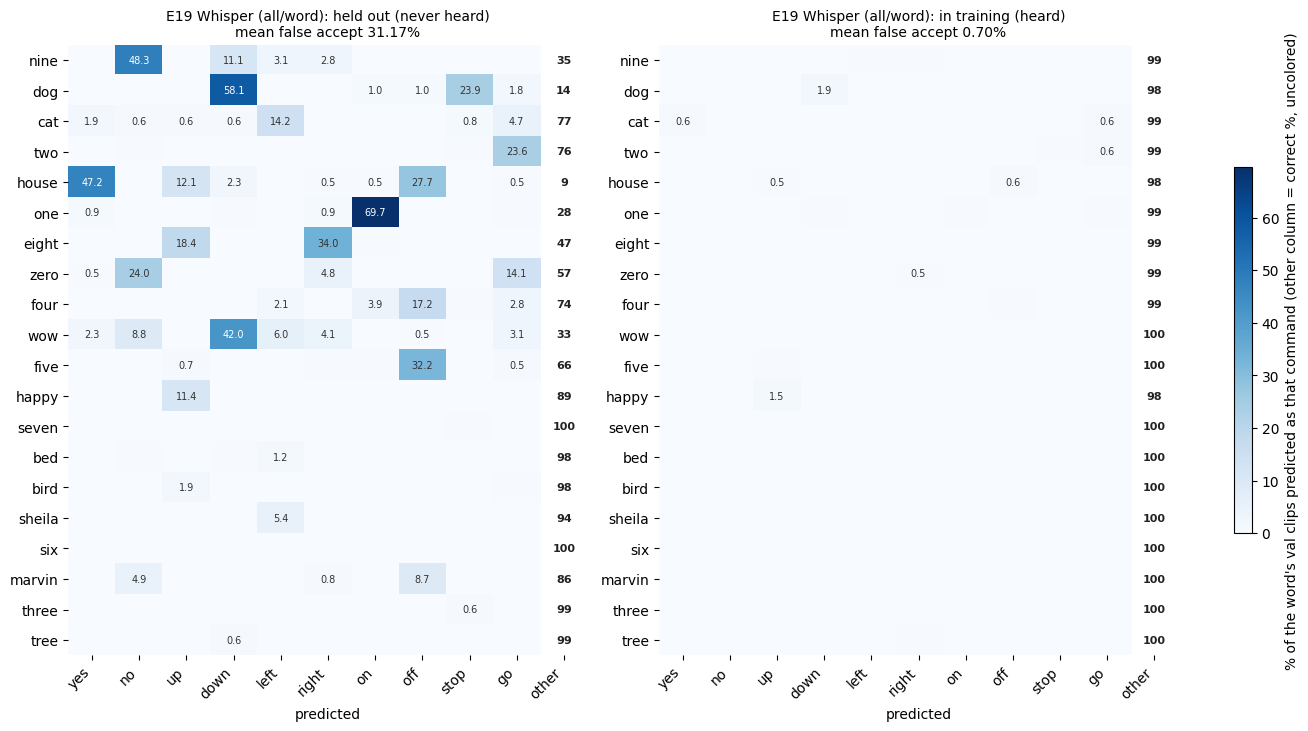

In [ ]:
# 셀 7. 단어마다: Whisper(E19, 전부)가 처음 들을 때 / 들었을 때 오작동, 09의 CNN과 나란히
# CNN 값은 09_처음듣는단어_흉내_결과.ipynb 셀 7 출력에서 옮김 (같은 단어를 학습에서 뺐을 때, 시드 2개 평균)
CNN09 = {"E15": {"nine": .4270, "dog": .7310, "cat": .2972, "two": .2464, "house": .0718, "one": .3647, "eight": .1821,
                 "zero": .0560, "four": .1448, "wow": .3446, "five": .1935, "happy": .0799, "seven": .1705, "bed": .1714,
                 "bird": .1703, "sheila": .0294, "six": .0265, "marvin": .1410, "three": .0253, "tree": .0031},
         "E16": {"nine": .6461, "dog": .6294, "cat": .3611, "two": .2855, "house": .2385, "one": .2365, "eight": .1936,
                 "zero": .1745, "four": .1166, "wow": .1166, "five": .1158, "happy": .1073, "seven": .0917, "bed": .0751,
                 "bird": .0632, "sheila": .0441, "six": .0238, "marvin": .0205, "three": .0056, "tree": .0000}}
WORDS = sorted(DIGITS + AUX)
oth = L2I[OTHER]
def word_matrix(runs, heldout):
    M = np.zeros((len(WORDS), K))
    for wi, w in enumerate(WORDS):
        mw = VAL_WORD == w
        rs = [r for r in runs if (w in r["held"]) == heldout]
        M[wi] = np.mean([np.bincount(r["pred"][mw], minlength=K) / mw.sum() * 100 for r in rs], axis=0)
    return M
WM = {ho: word_matrix(RUNS_W["E19"], ho) for ho in [True, False]}
WM18 = word_matrix(RUNS_W["E18"], True)

rows = []
for wi, w in enumerate(WORDS):
    Mh = WM[True][wi]
    top = [j for j in np.argsort(-Mh) if j != oth][:3]
    rows.append({"단어": w, "CNN E16 처음 (09)": CNN09["E16"][w] * 100, "Whisper E19 처음": 100 - Mh[oth],
                 "Whisper E19 들었을 때": 100 - WM[False][wi][oth],
                 "CNN E15 처음 (09)": CNN09["E15"][w] * 100, "Whisper E18 처음": 100 - WM18[wi][oth],
                 "Whisper E19 처음일 때 많이 간 명령": ", ".join(f"{LABELS[j]} {Mh[j]:.1f}%" for j in top if Mh[j] > 0) or "-"})
wt = pd.DataFrame(rows).sort_values("CNN E16 처음 (09)", ascending=False)
print("단어마다 처음 들을 때 명령으로 샌 비율. 앞 세 열은 \"명령 아님\" 전부, 다음 두 열은 단어마다 153개")
print(wt.to_string(index=False, float_format=lambda v: f"{v:.1f}%"))

order = np.array([WORDS.index(w) for w in wt.단어])
vmax = max(np.delete(M, oth, axis=1).max() for M in WM.values())
fig, axes = plt.subplots(1, 2, figsize=(13, 7.2), constrained_layout=True)
for ax, ho in zip(axes, [True, False]):
    M = WM[ho][order]
    E = M.copy(); E[:, oth] = np.nan
    im = ax.imshow(E, cmap="Blues", vmin=0, vmax=max(vmax, 1), aspect="auto")
    for i in range(len(WORDS)):
        for j in range(K):
            v = M[i, j]
            if j == oth:
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, fontweight="bold", color="#222")
            elif v >= 0.5:
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if v > vmax * 0.6 else "#333")
    ax.set_xticks(range(K)); ax.set_xticklabels(LABELS, rotation=45, ha="right")
    ax.set_yticks(range(len(WORDS))); ax.set_yticklabels(np.array(WORDS)[order])
    ax.set_title("E19 Whisper (all/word): " + ("held out (never heard)" if ho else "in training (heard)")
                 + f"\nmean false accept {100 - M[:, oth].mean():.2f}%", fontsize=10)
    ax.set_xlabel("predicted")
    for s_ in ax.spines.values():
        s_.set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.6, label="% of the word's val clips predicted as that command (other column = correct %, uncolored)")
os.makedirs("figs", exist_ok=True)
fig.savefig("figs/10_whisper_word_confusion.png", dpi=150)
plt.show()

In [ ]:
# 셀 8. E20 (CNN) · E21 (Whisper): 닮은 짝을 함께 빼기, 둘 다 "명령 아님" 전부, 시드 3개
# 혼자 뺐을 때 값: CNN은 09의 E16, Whisper는 셀 6의 E19 (둘 다 같은 녹음 조건, 그 단어 묶음의 다른 4개 단어도 함께 빠졌던 조건)
pair_rows = []
for pair in PAIRS:
    for seed in SEEDS_PAIR:
        best, h = train_cnn(train_mask(CONDS["E16"], pair), seed, pair)
        bw = fit_linear(pair, seed, *DATA_W["전부"])
        for w in pair:
            pair_rows.append({"짝": "+".join(pair), "단어": w, "시드": seed, "CNN 함께 뺌": word_fa(best["pred"], w), "Whisper 함께 뺌": word_fa(bw["pred"], w)})
        print(f"{'+'.join(pair)} 시드 {seed}: CNN (최고 {best['epoch']}에폭, 에폭당 {h.sec.mean():.1f}초) "
              + ", ".join(f"{w} {word_fa(best['pred'], w):.2%}" for w in pair)
              + f" | Whisper (최고 {bw['epoch']}에폭) " + ", ".join(f"{w} {word_fa(bw['pred'], w):.2%}" for w in pair))
pr = pd.DataFrame(pair_rows)
summ = pr.groupby(["짝", "단어"], sort=False)[["CNN 함께 뺌", "Whisper 함께 뺌"]].agg(["mean", "std"])
out = []
for (pair, w), r in summ.iterrows():
    w_alone = np.mean([word_fa(x["pred"], w) for x in RUNS_W["E19"] if w in x["held"]])
    out.append({"짝": pair, "단어": w,
                "CNN 혼자 뺌 (09 E16)": f"{CNN09['E16'][w]:.2%}",
                "CNN 함께 뺌 (E20)": f"{r[('CNN 함께 뺌', 'mean')]:.2%} ± {r[('CNN 함께 뺌', 'std')]:.2%}",
                "Whisper 혼자 뺌 (E19)": f"{w_alone:.2%}",
                "Whisper 함께 뺌 (E21)": f"{r[('Whisper 함께 뺌', 'mean')]:.2%} ± {r[('Whisper 함께 뺌', 'std')]:.2%}"})
print()
print(pd.DataFrame(out).to_string(index=False))
print("SMOKE 모드 결과 (숫자를 쓰지 말 것)" if SMOKE else f"시드 {SEEDS_PAIR} | 검증 {len(val):,}개 | CNN 20에폭 · Whisper Linear {LIN_EPOCHS}에폭")

three+tree 시드 0: CNN (최고 15에폭, 에폭당 6.7초) three 1.40%, tree 0.00% | Whisper (최고 17에폭) three 2.81%, tree 2.52%
three+tree 시드 1: CNN (최고 19에폭, 에폭당 6.9초) three 0.56%, tree 0.63% | Whisper (최고 21에폭) three 4.21%, tree 2.52%
three+tree 시드 2: CNN (최고 17에폭, 에폭당 6.9초) three 5.34%, tree 0.63% | Whisper (최고 28에폭) three 7.02%, tree 1.89%
bed+bird 시드 0: CNN (최고 14에폭, 에폭당 7.0초) bed 10.80%, bird 3.85% | Whisper (최고 29에폭) bed 2.82%, bird 6.59%
bed+bird 시드 1: CNN (최고 15에폭, 에폭당 7.0초) bed 5.16%, bird 4.40% | Whisper (최고 25에폭) bed 2.82%, bird 4.40%
bed+bird 시드 2: CNN (최고 16에폭, 에폭당 7.0초) bed 5.63%, bird 4.95% | Whisper (최고 22에폭) bed 3.29%, bird 5.49%

         짝    단어 CNN 혼자 뺌 (09 E16) CNN 함께 뺌 (E20) Whisper 혼자 뺌 (E19) Whisper 함께 뺌 (E21)
three+tree three             0.56%  2.43% ± 2.55%              0.70%      4.68% ± 2.15%
three+tree  tree             0.00%  0.42% ± 0.36%              0.63%      2.31% ± 0.36%
  bed+bird   bed             7.51%  7.20% ± 3.13%              2.11%      2.97% ± 0.27%
  bed+bird